**Data Preparation**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from google.colab import files
uploaded = files.upload()

Saving customer_master.csv to customer_master.csv
Saving dataset_statistics.csv to dataset_statistics.csv
Saving ecommerce_sales_customer_analytics_150k.csv to ecommerce_sales_customer_analytics_150k.csv
Saving order_items.csv to order_items.csv
Saving product_catalog.csv to product_catalog.csv


In [5]:
customers = pd.read_csv("customer_master.csv")
dataset_stats = pd.read_csv("dataset_statistics.csv")
sales = pd.read_csv("ecommerce_sales_customer_analytics_150k.csv")
order_items = pd.read_csv("order_items.csv")
products = pd.read_csv("product_catalog.csv")

In [6]:
print("Customers:", customers.shape)
print("Dataset Statistics:", dataset_stats.shape)
print("Sales:", sales.shape)
print("Order Items:", order_items.shape)
print("Products:", products.shape)

Customers: (25000, 11)
Dataset Statistics: (1, 11)
Sales: (138116, 46)
Order Items: (397569, 12)
Products: (1175, 9)


In [7]:
print("CUSTOMERS")
print(customers.columns.tolist())

print("DATASET STATISTICS")
print(dataset_stats.columns.tolist())

print("SALES")
print(sales.columns.tolist())

print("ORDER ITEMS")
print(order_items.columns.tolist())

print("PRODUCTS")
print(products.columns.tolist())

CUSTOMERS
['customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'customer_acquisition_cost']
DATASET STATISTICS
['Total Transactions', 'Total Columns', 'Total Customers', 'Total Products Used', 'Date Range', 'Total Revenue', 'Total Profit', 'Average Order Value', 'Average Rating', 'Return Rate', 'Cancellation Rate']
SALES
['order_id', 'order_date', 'order_time', 'order_status', 'sales_channel', 'customer_id', 'customer_name', 'customer_age', 'gender', 'customer_segment', 'customer_type', 'customer_city', 'customer_state', 'customer_country', 'region', 'customer_postal_code', 'payment_method', 'payment_status', 'currency', 'shipping_method', 'warehouse', 'delivery_days', 'estimated_delivery_days', 'delivery_status', 'return_status', 'return_reason', 'customer_rating', 'review_sentiment', 'customer_review', 'marketing_channel', 'campaign_name', 'coupon_code', 'loyalty_points_

In [8]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                25000 non-null  object 
 1   customer_name              25000 non-null  object 
 2   customer_age               25000 non-null  int64  
 3   gender                     25000 non-null  object 
 4   customer_segment           25000 non-null  object 
 5   customer_city              25000 non-null  object 
 6   customer_state             25000 non-null  object 
 7   customer_country           25000 non-null  object 
 8   region                     25000 non-null  object 
 9   customer_postal_code       25000 non-null  int64  
 10  customer_acquisition_cost  25000 non-null  float64
dtypes: float64(1), int64(2), object(8)
memory usage: 2.1+ MB


In [9]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 138116 entries, 0 to 138115
Data columns (total 46 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   order_id                  138116 non-null  object 
 1   order_date                138116 non-null  object 
 2   order_time                138116 non-null  object 
 3   order_status              138116 non-null  object 
 4   sales_channel             138116 non-null  object 
 5   customer_id               138116 non-null  object 
 6   customer_name             138116 non-null  object 
 7   customer_age              138116 non-null  int64  
 8   gender                    138116 non-null  object 
 9   customer_segment          138116 non-null  object 
 10  customer_type             138116 non-null  object 
 11  customer_city             138116 non-null  object 
 12  customer_state            138116 non-null  object 
 13  customer_country          138116 non-null  o

In [10]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 397569 entries, 0 to 397568
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             397569 non-null  object 
 1   product_id           397569 non-null  object 
 2   quantity             397569 non-null  int64  
 3   unit_price           397569 non-null  float64
 4   discount_percentage  397569 non-null  float64
 5   discount_amount      397569 non-null  float64
 6   gross_sales          397569 non-null  float64
 7   tax_amount           397569 non-null  float64
 8   shipping_cost        397569 non-null  float64
 9   net_sales            397569 non-null  float64
 10  product_cost         397569 non-null  float64
 11  profit               397569 non-null  float64
dtypes: float64(9), int64(1), object(2)
memory usage: 36.4+ MB


In [11]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1175 entries, 0 to 1174
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   product_id           1175 non-null   object 
 1   product_name         1175 non-null   object 
 2   product_category     1175 non-null   object 
 3   product_subcategory  1175 non-null   object 
 4   brand                1175 non-null   object 
 5   supplier             1175 non-null   object 
 6   unit_price           1175 non-null   float64
 7   product_cost         1175 non-null   float64
 8   product_rating       1175 non-null   float64
dtypes: float64(3), object(6)
memory usage: 82.7+ KB


In [12]:
print("Customers IDs Unique:",customers["customer_id"].is_unique)
print("Duplicate Customer IDs:",customers["customer_id"].duplicated().sum())

Customers IDs Unique: True
Duplicate Customer IDs: 0


In [13]:
print("Order IDs Unique:", sales["order_id"].is_unique)
print("Duplicate Order IDs:", sales["order_id"].duplicated().sum())

Order IDs Unique: True
Duplicate Order IDs: 0


In [14]:
print("Order + Product duplicate rows:",order_items[["order_id", "product_id"]].duplicated().sum())

Order + Product duplicate rows: 87


In [15]:
print("Product IDs Unique:", products["product_id"].is_unique)
print("Duplicate Product IDs:", products["product_id"].duplicated().sum())

Product IDs Unique: True
Duplicate Product IDs: 0


In [16]:
print("Sales Customers:", sales["customer_id"].nunique())
print("Master Customers:", customers["customer_id"].nunique())

print("Sales Orders:", sales["order_id"].nunique())
print("Order-Item Orders:", order_items["order_id"].nunique())

print("Order-Item Products:", order_items["product_id"].nunique())
print("Catalog Products:", products["product_id"].nunique())

Sales Customers: 24911
Master Customers: 25000
Sales Orders: 138116
Order-Item Orders: 138116
Order-Item Products: 1175
Catalog Products: 1175


In [17]:
sales_customers_not_in_master = (
    set(sales["customer_id"]) - set(customers["customer_id"]))

print(
    "Sales Customers Not In Customer Master:",len(sales_customers_not_in_master))

Sales Customers Not In Customer Master: 0


In [18]:
order_products_not_in_catalog = (
    set(order_items["product_id"]) - set(products["product_id"]))

print("Order-item products not in product catalog:",
    len(order_products_not_in_catalog))

Order-item products not in product catalog: 0


In [19]:
order_items_not_in_sales = (
    set(order_items["order_id"]) - set(sales["order_id"]))

print("Order-item orders not in sales:",
    len(order_items_not_in_sales))

Order-item orders not in sales: 0


In [20]:
sales["order_status"].value_counts(dropna=False)

,count
order_status,
Completed,113559
Returned,9462
Cancelled,8398
Pending,6697


In [21]:
sales["payment_status"].value_counts(dropna=False)

,count
payment_status,
Paid,104250
Pending,13975
Failed,10429
Refunded,9462


In [22]:
sales["delivery_status"].value_counts(dropna=False)

,count
delivery_status,
On Time,86916
Cancelled,24557
Delayed,16886
Early,9757


In [23]:
sales["return_status"].value_counts(dropna=False)

,count
return_status,
NaN,128654
Returned,9462


In [24]:
pd.crosstab(
    sales["order_status"],
    sales["payment_status"],
    dropna=False
)

payment_status,Failed,Paid,Pending,Refunded
order_status,,,,
Cancelled,8398,0,0,0
Completed,0,102253,11306,0
Pending,2031,1997,2669,0
Returned,0,0,0,9462


In [25]:
item_totals = (
    order_items
    .groupby("order_id")
    .agg(
        item_gross_sales=("gross_sales", "sum"),
        item_net_sales=("net_sales", "sum"),
        item_product_cost=("product_cost", "sum"),
        item_profit=("profit", "sum")
    )
    .reset_index()
)

In [26]:
reconciliation = sales[
    [
        "order_id",
        "gross_sales",
        "net_sales",
        "product_cost",
        "profit"
    ]
].merge(
    item_totals,
    on="order_id",
    how="left"
)

In [29]:
reconciliation["profit_diff"] = (
    reconciliation["profit"] - reconciliation["item_profit"])

In [28]:
profit_mismatch = (
    ~np.isclose(
        reconciliation["profit_diff"],
        0,
        atol=0.01
    )
).sum()

print("Orders with profit mismatch:", profit_mismatch)

Orders with profit mismatch: 11226


In [31]:
sales["calculated_margin"] = (
    sales["profit"] / sales["net_sales"] * 100
)

sales[
    ["profit_margin_percentage", "calculated_margin"]
].head(10)

,profit_margin_percentage,calculated_margin
0,36.50,36.496721
1,-1.11,-1.113253
2,42.18,42.184264
3,45.35,45.346922
4,54.94,54.944763
5,44.51,44.510020
6,51.48,51.477359
7,40.01,40.012032
8,43.53,43.533123
9,37.35,37.348568


In [32]:
margin_difference = (
    sales["profit_margin_percentage"] - sales["calculated_margin"])

margin_difference.describe()

,0
count,138116.000000
mean,-0.000004
std,0.002890
min,-0.005000
25%,-0.002507
50%,0.000005
75%,0.002501
max,0.005000


In [33]:
sales["order_date"] = pd.to_datetime(
    sales["order_date"],
    format="mixed",
    dayfirst=True,
    errors="coerce"
)

In [34]:
print("Invalid Dates:", sales["order_date"].isna().sum())

print(
    "Date Range:",
    sales["order_date"].min(),
    "to",
    sales["order_date"].max()
)

Invalid Dates: 0
Date Range: 2021-01-01 00:00:00 to 2025-12-31 00:00:00


In [35]:
missing_values = sales.isna().sum()

missing_values = missing_values[missing_values > 0].sort_values(
    ascending=False
)

missing_values

,0
return_status,128654
return_reason,128654
coupon_code,110502
campaign_name,83233
delivery_days,24557
customer_rating,24557
estimated_delivery_days,24557
customer_review,24557
review_sentiment,24557


In [36]:
sales_clean = sales.copy()

In [37]:
print("Negative Quantities:", (sales_clean["quantity"] < 0).sum())
print("Negative Prices:", (sales_clean["gross_sales"] < 0).sum())
print("Negative Shipping Costs:", (sales_clean["shipping_cost"] < 0).sum())
print("Negative Product Costs:", (sales_clean["product_cost"] < 0).sum())

Negative Quantities: 0
Negative Prices: 0
Negative Shipping Costs: 0
Negative Product Costs: 0


In [38]:
print("Ratings Below 1:", (sales_clean["customer_rating"] < 1).sum())
print("Ratings Above 5:", (sales_clean["customer_rating"] > 5).sum())

Ratings Below 1: 0
Ratings Above 5: 0


In [39]:
print("Quantities Equal To 0:", (sales_clean["quantity"] == 0).sum())

Quantities Equal To 0: 0


In [40]:
print("Order Status:")
print(sales_clean["order_status"].unique())

print("Sales Channel:")
print(sales_clean["sales_channel"].unique())

print("Customer Segment:")
print(sales_clean["customer_segment"].unique())

print("Customer Type:")
print(sales_clean["customer_type"].unique())

print("Marketing Channel:")
print(sales_clean["marketing_channel"].unique())

print("Shipping Method:")
print(sales_clean["shipping_method"].unique())

print("Delivery Status:")
print(sales_clean["delivery_status"].unique())

Order Status:
['Completed' 'Pending' 'Cancelled' 'Returned']
Sales Channel:
['Mobile App' 'Website' 'Social Media' 'Marketplace']
Customer Segment:
['Consumer' 'Premium' 'VIP' 'Business']
Customer Type:
['Loyal' 'Returning' 'New']
Marketing Channel:
['Direct' 'YouTube' 'Email Marketing' 'Organic Search' 'Referral'
 'Google Ads' 'Facebook Ads' 'TikTok' 'Instagram' 'Affiliate']
Shipping Method:
['Standard' 'Economy' 'Express' 'Same Day']
Delivery Status:
['On Time' 'Delayed' 'Cancelled' 'Early']


In [41]:
print("Order Dates Unique:", sales_clean["order_date"].nunique())
print("Orders:", sales_clean["order_id"].nunique())

Order Dates Unique: 1826
Orders: 138116


In [42]:
sales_clean["year"] = sales_clean["order_date"].dt.year
sales_clean["month"] = sales_clean["order_date"].dt.month
sales_clean["month_name"] = sales_clean["order_date"].dt.month_name()
sales_clean["quarter"] = sales_clean["order_date"].dt.quarter

In [43]:
sales_clean[
    ["order_date", "year", "month", "month_name", "quarter"]
].head()

,order_date,year,month,month_name,quarter
0,2023-11-06,2023,11,November,4
1,2025-12-24,2025,12,December,4
2,2021-07-05,2021,7,July,3
3,2023-01-21,2023,1,January,1
4,2022-05-13,2022,5,May,2


**Sales & Profitability**

In [45]:
total_orders = sales_clean["order_id"].nunique()
total_customers = sales_clean["customer_id"].nunique()
total_quantity = sales_clean["quantity"].sum()

print("Total Orders:", total_orders)
print("Customers With Orders:", total_customers)
print("Total Quantity:", total_quantity)

Total Orders: 138116
Customers With Orders: 24911
Total Quantity: 775555


In [46]:
yearly_sales = sales_clean.groupby("year").agg(
    orders=("order_id", "nunique"),
    customers=("customer_id", "nunique"),
    quantity=("quantity", "sum")
).reset_index()

yearly_sales

,year,orders,customers,quantity
0,2021,27554,16635,155745
1,2022,27564,16793,154796
2,2023,27632,16767,154813
3,2024,27768,16818,155762
4,2025,27598,16717,154439


In [47]:
monthly_sales = sales_clean.groupby(
    sales_clean["order_date"].dt.to_period("M")
).agg(
    orders=("order_id", "nunique"),
    customers=("customer_id", "nunique"),
    quantity=("quantity", "sum")
).reset_index()

monthly_sales["order_date"] = (
    monthly_sales["order_date"].dt.to_timestamp())

monthly_sales.head()

,order_date,orders,customers,quantity
0,2021-01-01,1906,1824,9569
1,2021-02-01,1565,1513,7809
2,2021-03-01,2166,2100,10890
3,2021-04-01,1943,1871,9940
4,2021-05-01,2096,2003,10538


In [48]:
print("Number Of Months:", len(monthly_sales))

Number Of Months: 60


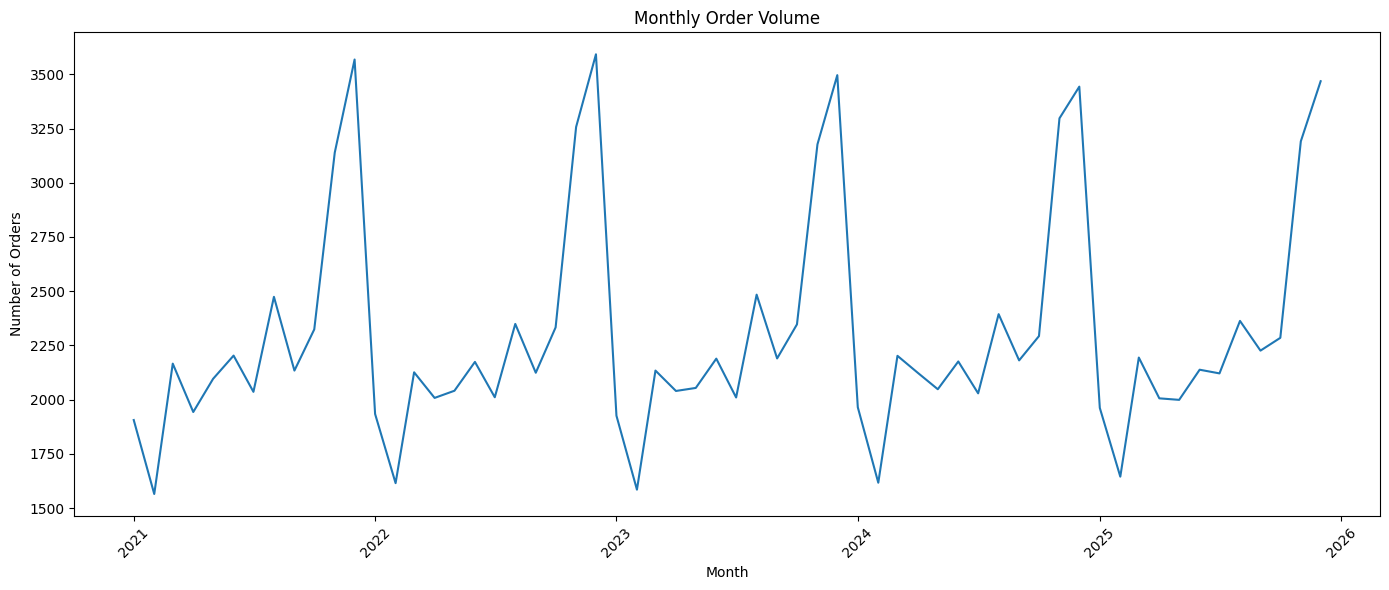

In [49]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales["order_date"],
    monthly_sales["orders"])

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [50]:
order_items_products = order_items.merge(
    products[["product_id", "product_category"]],
    on="product_id",
    how="left"
)

In [52]:
category_sales = order_items_products.groupby(
    "product_category"
).agg(
    quantity=("quantity", "sum"),
    sales_lines=("order_id", "count")
).reset_index()

category_sales = category_sales.sort_values(
    "quantity",
    ascending=False
)

category_sales

,product_category,quantity,sales_lines
13,Sports & Outdoors,64752,30594
3,Books & Media,62305,29363
7,Health & Wellness,62054,29188
2,Beauty & Personal Care,59765,28107
0,Automotive,58046,27480
11,Office Supplies,57631,27237
9,Home Appliances,56281,26406
14,Toys & Games,55788,26390
4,Electronics,55784,26387
6,Grocery,55607,26366


In [53]:
order_items_products = order_items.merge(
    products[
        [
            "product_id",
            "product_name",
            "product_category",
            "product_subcategory",
            "brand"
        ]
    ],
    on="product_id",
    how="left"
)

In [54]:
product_sales = order_items_products.groupby(
    [
        "product_id",
        "product_name",
        "product_category",
        "product_subcategory",
        "brand"
    ]
).agg(
    quantity=("quantity", "sum"),
    sales_lines=("order_id", "count")
).reset_index()

product_sales = product_sales.sort_values(
    "quantity",
    ascending=False
)

product_sales.head(10)

,product_id,product_name,product_category,product_subcategory,brand,quantity,sales_lines
838,PROD-000839,Arm & Hammer Organized maximized software Groo...,Pet Supplies,Grooming,Arm & Hammer,904,414
2,PROD-000003,LG Face-to-face client-driven support Smartphones,Electronics,Smartphones,LG,865,395
693,PROD-000694,Goodyear Managed clear-thinking secured line T...,Automotive,Tools,Goodyear,854,387
448,PROD-000449,Adidas Public-key homogeneous functionalities ...,Sports & Outdoors,Team Sports,Adidas,846,393
548,PROD-000549,HarperCollins Operative multi-tasking budgetar...,Books & Media,Movies,HarperCollins,844,381
877,PROD-000878,Graco Networked reciprocal instruction set Dia...,Baby & Kids,Diapers,Graco,841,380
927,PROD-000928,Evenflo Customizable content-based adapter Str...,Baby & Kids,Strollers,Evenflo,835,373
374,PROD-000375,Target Distributed encompassing circuit Lighting,Home & Kitchen,Lighting,Target,826,384
596,PROD-000597,Barbie Enterprise-wide encompassing standardiz...,Toys & Games,Dolls,Barbie,825,379
882,PROD-000883,Gerber Proactive fault-tolerant methodology Di...,Baby & Kids,Diapers,Gerber,825,374


In [55]:
segment_sales = sales_clean.groupby(
    "customer_segment"
).agg(
    orders=("order_id", "nunique"),
    customers=("customer_id", "nunique"),
    quantity=("quantity", "sum")
).reset_index()

segment_sales

,customer_segment,orders,customers,quantity
0,Business,13777,2515,75840
1,Consumer,75636,13585,417201
2,Premium,34746,6275,201448
3,VIP,13957,2536,81066
